In [5]:
%pip install torch torchvision torchaudio scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.6/73.6 MB 6.4 MB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 8.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 5.4 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 4.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 4.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 5.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [torchaudio]8 [torchaudio]]
Note: you may need to restart the kernel to use updated packages.


# Import & Configuration

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import sys
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

# Add src to path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from feature_eng import DataProcessor
from model import RULPredictor

# --- HYPERPARAMETERS ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 100
BATCH_SIZE = 32
WINDOW_SIZE = 30
LEARNING_RATE = 0.001

print(f"Training Device: {DEVICE}")

Training Device: cpu


# Data Preparation (Using DataLoader)

In [21]:
# 1. Prepare Data
print("Loading and processing data...")
processor = DataProcessor(window_size=WINDOW_SIZE)

# Check if processed data exists
if os.path.exists("../data/processed/final_features.csv"):
    feat_df = pd.read_csv("../data/processed/final_features.csv")
    print(" Loaded processed data from disk.")
else:
    from data_loader import load_all_data
    raw_df = load_all_data("../data/raw")
    feat_df = processor.extract_features(raw_df)

# Convert to LSTM Format
X, y, scaler = processor.prepare_lstm_data(feat_df)

# Convert to Tensors
X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y).view(-1, 1)

# Train/Val Split (Shuffle is crucial here!)
X_train, X_val, y_train, y_val = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# Create DataLoaders (Mini-Batch Training)
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train Samples: {len(X_train)} | Validation Samples: {len(X_val)}")

Loading and processing data...
 Loaded processed data from disk.
Creating LSTM Sequences...
 LSTM Data Prepared! X: (839, 30, 4), y: (839,)
Train Samples: 671 | Validation Samples: 168


# Training Loop

In [24]:
# 2. Initialize Model
model = RULPredictor(input_dim=4, hidden_dim=64).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

# 3. Start Training
train_losses = []
val_losses = []

print("Starting Training Loop...")

for epoch in range(EPOCHS):
    # --- TRAIN ---
    model.train()
    batch_losses = []
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
        
        optimizer.zero_grad()
        preds, _ = model(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        batch_losses.append(loss.item())
    
    # Calculate average loss for this epoch
    avg_train_loss = np.mean(batch_losses)
    train_losses.append(avg_train_loss)
    
    # --- VALIDATION ---
    model.eval()
    val_batch_losses = []
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
            val_preds, _ = model(batch_X)
            val_loss = criterion(val_preds, batch_y)
            val_batch_losses.append(val_loss.item())
            
    avg_val_loss = np.mean(val_batch_losses)
    val_losses.append(avg_val_loss)
        
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

# Save the notebook-trained model
if not os.path.exists("../models"):
    os.makedirs("../models")
torch.save(model.state_dict(), "../models/best_model_notebook.pth")
print(" Training Complete. Model saved to models/best_model_notebook.pth")

Starting Training Loop...
Epoch 10/100 | Train Loss: 1466.2214 | Val Loss: 1443.1738
Epoch 20/100 | Train Loss: 1126.3418 | Val Loss: 1164.5816
Epoch 30/100 | Train Loss: 775.9088 | Val Loss: 498.0416
Epoch 40/100 | Train Loss: 187.8500 | Val Loss: 193.5905
Epoch 50/100 | Train Loss: 115.9666 | Val Loss: 138.0898
Epoch 60/100 | Train Loss: 99.2753 | Val Loss: 61.8465
Epoch 70/100 | Train Loss: 56.4853 | Val Loss: 45.4306
Epoch 80/100 | Train Loss: 57.6690 | Val Loss: 51.1956
Epoch 90/100 | Train Loss: 44.7633 | Val Loss: 37.2848
Epoch 100/100 | Train Loss: 42.6129 | Val Loss: 31.0396
 Training Complete. Model saved to models/best_model_notebook.pth


# Plot Loss Curve 

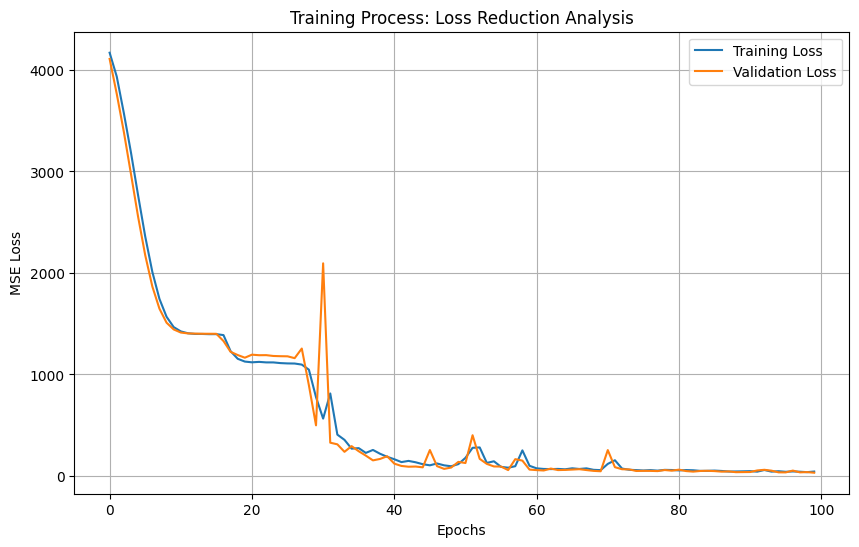

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training Process: Loss Reduction Analysis')
plt.legend()
plt.grid(True)
plt.show()